# Komparasi statistik LC-4 dan LC-50kg

Dua berkas LabVIEW direkam bersamaan (23 Nov 2026, ~21:03):

- `LC-4 Pressure-Kal.txt` — channel `LC-4-JYS60_cDaq9205`
- `LC-50kg Pressure-Kal.txt` — channel `LC_50kg_PVDF2x2_2026_cDaq9237`

Keduanya gaya dalam kg, ~2000 sampel/detik, durasi ~23,7 detik, berisi tangga beban (beberapa sentuhan terpisah).

## Apa yang dibandingkan

Perbandingan dilakukan pada tiga hal yang menentukan pemakaian sebagai touchpad timer:

1. **Lantai noise** saat tidak ada beban — batas aman ambang deteksi.
2. **Waktu tembus ambang** tiap sentuhan — selisih ini langsung menjadi kesalahan waktu sentuh.
3. **Amplitudo tiap sentuhan** (puncak dan impuls) — apakah skala kg kedua sensor setuju, dan apakah rasio itu berubah mengikuti besar beban.

Kesepakatan angka diringkas dengan **Pearson r** (apakah keduanya naik bersama) dan **MAE** (rata-rata selisih mutlak, dalam kg). Keduanya dihitung pada puncak sembilan sentuhan dan pada gelombang yang sudah diselaraskan waktunya.

Rata-rata seluruh rekaman sengaja tidak dipakai sebagai metrik utama: sebagian besar sampel adalah istirahat, sehingga rata-rata global hampir hanya mencerminkan tara.

Pada regresi, LC-50kg diletakkan di sumbu x sebagai pembanding (modul jembatan cDAQ-9237). Itu pilihan sumbu, bukan bukti bahwa sensor tersebut yang benar. Tanpa massa acuan, data ini mengukur kesepakatan antar sensor, bukan akurasi terhadap kilogram yang sebenarnya.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import signal, stats

DATA_DIR = Path("d:/Pengujian/Swimmer_Monitoring/Touchpad_Timer_Pressure/Pad_Comparison")
FILES = {
    "LC-4": DATA_DIR / "LC-4 Pressure-Kal.txt",
    "LC-50kg": DATA_DIR / "LC-50kg Pressure-Kal.txt",
}

# Jendela istirahat sebelum sentuhan pertama (~3,9 s).
REST_END_S = 3.5
BASELINE_END_S = 2.0

# Deteksi event pada rata-rata geser simetris. Filter yang sama di kedua
# sensor tidak menambah selisih waktu antar kanal.
SMOOTH_S = 0.010
ON_KG = 0.8
OFF_KG = 0.35
MIN_DUR_S = 0.05
MIN_PEAK_KG = 1.0
MAX_PAIR_S = 0.5
PRE_ROLL_S = 0.25

THRESHOLDS_KG = [0.5, 1, 2, 5, 10, 15, 20, 25]
MAX_LAG_S = 0.25

C = {"LC-4": "#1f4e79", "LC-50kg": "#d35400"}

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "lines.linewidth": 1.0,
})


def read_lvm(path: Path):
    meta = {}
    rows_t = []
    rows_y = []
    in_data = False
    channel = path.stem
    with path.open(encoding="utf-8", errors="replace") as handle:
        for line in handle:
            raw = line.rstrip("\n\r")
            if raw.startswith("X_Value"):
                parts = [p.strip() for p in raw.split("\t") if p.strip()]
                if len(parts) >= 2:
                    channel = parts[1]
                in_data = True
                continue
            if not in_data:
                if "\t" in raw:
                    key, value = raw.split("\t", 1)
                    meta[key.strip()] = value.strip()
                continue
            parts = raw.split("\t")
            if len(parts) < 2 or not parts[0].strip():
                continue
            try:
                rows_t.append(float(parts[0]))
                rows_y.append(float(parts[1]))
            except ValueError:
                continue
    df = pd.DataFrame({"t_s": rows_t, "kg": rows_y})
    meta["channel"] = channel
    meta["file"] = path.name
    return meta, df


def moving_average(y, dt, width_s):
    n = max(1, int(round(width_s / dt)))
    if n % 2 == 0:
        n += 1
    kernel = np.ones(n) / n
    return np.convolve(y, kernel, mode="same"), n


def hysteresis_mask(smooth, on_level, off_level):
    mask = np.zeros(len(smooth), dtype=bool)
    state = False
    for i, value in enumerate(smooth):
        if state:
            if value <= off_level:
                state = False
            else:
                mask[i] = True
        elif value >= on_level:
            state = True
            mask[i] = True
    return mask


def segments_from_mask(mask):
    edges = np.diff(mask.astype(np.int8), prepend=0, append=0)
    starts = np.flatnonzero(edges == 1)
    ends = np.flatnonzero(edges == -1)
    return list(zip(starts, ends))


def crossing_time(t, y, level):
    if len(y) == 0 or y[0] >= level:
        return np.nan
    idx = np.flatnonzero(y >= level)
    if len(idx) == 0:
        return np.nan
    i = int(idx[0])
    y0, y1 = float(y[i - 1]), float(y[i])
    if y1 == y0:
        return float(t[i])
    frac = (level - y0) / (y1 - y0)
    return float(t[i - 1] + frac * (t[i] - t[i - 1]))


def lin_ccc(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mx, my = x.mean(), y.mean()
    vx = x.var(ddof=1)
    vy = y.var(ddof=1)
    sxy = np.cov(x, y, ddof=1)[0, 1]
    return float(2 * sxy / (vx + vy + (mx - my) ** 2))


def header_clock_s(meta):
    clock = meta.get("Time", "")
    try:
        hh, mm, ss = clock.split(":")
        return int(hh) * 3600 + int(mm) * 60 + float(ss)
    except ValueError:
        return np.nan

## 1. Akuisisi

Header LabVIEW dibaca, tetapi interval sampel dan jumlah sampel diambil dari kolom waktu. Pada berkas LC-4, `Delta_X` di header tidak sama dengan selisih waktu di data.

In [2]:
raw = {}
for name, path in FILES.items():
    meta, df = read_lvm(path)
    t = df["t_s"].to_numpy()
    y = df["kg"].to_numpy()
    dt = float(np.median(np.diff(t)))
    baseline = float(np.median(y[t < BASELINE_END_S]))
    smooth, smooth_n = moving_average(y - baseline, dt, SMOOTH_S)
    raw[name] = {
        "meta": meta,
        "t": t,
        "y": y,
        "dt": dt,
        "fs": 1.0 / dt,
        "baseline": baseline,
        "force": y - baseline,
        "smooth": smooth,
        "smooth_n": smooth_n,
    }

rows = []
for name, item in raw.items():
    t = item["t"]
    rest = item["force"][t < REST_END_S]
    header_dx = item["meta"].get("Delta_X", "")
    rows.append({
        "sensor": name,
        "berkas": item["meta"]["file"],
        "channel": item["meta"]["channel"],
        "tanggal": item["meta"].get("Date", ""),
        "jam_header": item["meta"].get("Time", ""),
        "n": len(t),
        "n_header": item["meta"].get("Samples", ""),
        "t_awal_s": t[0],
        "t_akhir_s": t[-1],
        "durasi_s": t[-1] - t[0],
        "fs_Hz": item["fs"],
        "dt_ms": item["dt"] * 1e3,
        "Delta_X_header": header_dx,
        "baseline_kg": item["baseline"],
        "noise_rms_kg": float(np.sqrt(np.mean(rest ** 2))),
        "noise_puncak_kg": float(rest.max()),
        "y_min_kg": float(item["y"].min()),
        "y_maks_kg": float(item["y"].max()),
    })

akuisisi = pd.DataFrame(rows).set_index("sensor")
display(akuisisi.T)

clock_ms = (header_clock_s(raw["LC-4"]["meta"]) - header_clock_s(raw["LC-50kg"]["meta"])) * 1e3
print(f"Selisih jam header (LC-4 minus LC-50kg): {clock_ms:.2f} ms")
print(
    "Rata-rata geser: "
    f"{raw['LC-4']['smooth_n']} sampel "
    f"({raw['LC-4']['smooth_n'] * raw['LC-4']['dt'] * 1e3:.1f} ms), simetris."
)

for name, item in raw.items():
    try:
        header_dx = float(item["meta"].get("Delta_X", "nan"))
    except ValueError:
        header_dx = np.nan
    if np.isfinite(header_dx) and abs(header_dx - item["dt"]) / item["dt"] > 0.01:
        print(
            f"{name}: Delta_X header = {header_dx:g} s, "
            f"dt data = {item['dt'] * 1e3:.3f} ms. Analisis memakai kolom waktu."
        )

sensor,LC-4,LC-50kg
berkas,LC-4 Pressure-Kal.txt,LC-50kg Pressure-Kal.txt
channel,LC-4-JYS60_cDaq9205,LC_50kg_PVDF2x2_2026_cDaq9237
tanggal,2026/11/23,2026/11/23
jam_header,21:03:55.1961536407470703125,21:03:55.194659199999847684
n,47230,47400
n_header,0,200
t_awal_s,0.0005,0.0
t_akhir_s,23.615,23.6995
durasi_s,23.6145,23.6995
fs_Hz,2000.0,2000.0


Selisih jam header (LC-4 minus LC-50kg): 1.49 ms
Rata-rata geser: 21 sampel (10.5 ms), simetris.
LC-4: Delta_X header = 1 s, dt data = 0.500 ms. Analisis memakai kolom waktu.


## 2. Bentuk sinyal

Gaya di bawah sudah dikurangi tara (median 2 detik pertama). Sentuhan terlihat sebagai pulsa terpisah. Panel bawah memperbesar masa istirahat supaya lantai noise kedua sensor bisa dibandingkan pada skala yang sama.

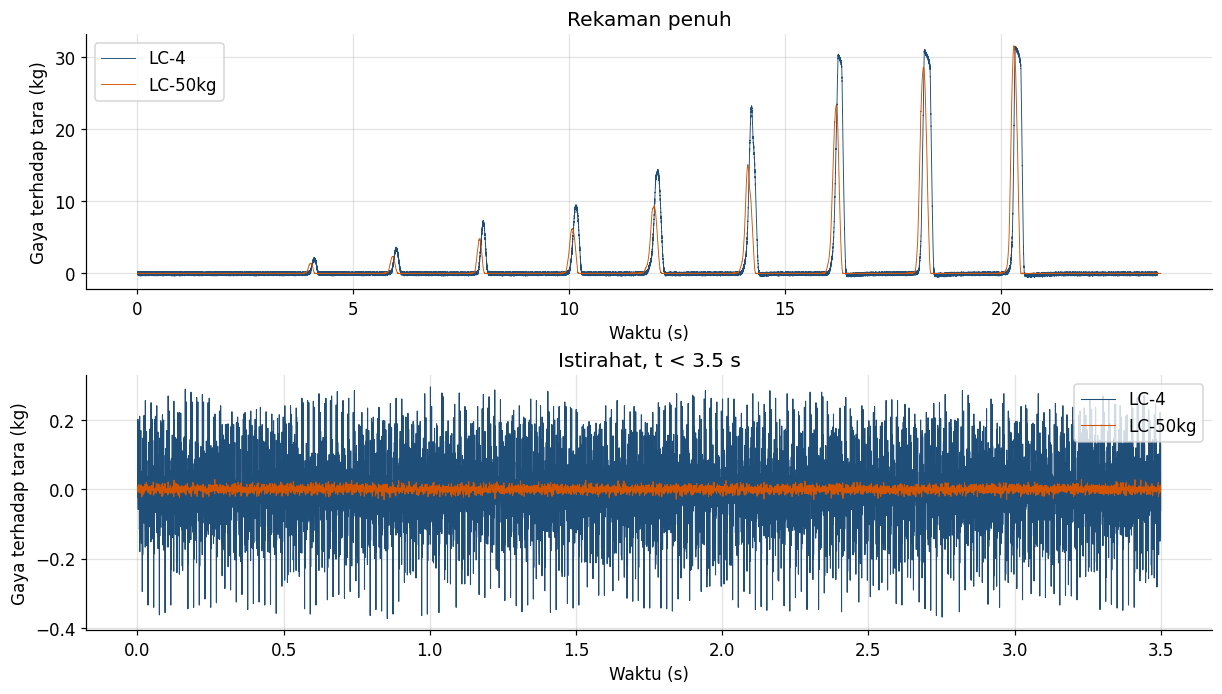

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.2), sharex=False, constrained_layout=True)

ax = axes[0]
for name, item in raw.items():
    ax.plot(item["t"], item["force"], color=C[name], lw=0.6, label=name)
ax.set_ylabel("Gaya terhadap tara (kg)")
ax.set_xlabel("Waktu (s)")
ax.set_title("Rekaman penuh")
ax.legend(loc="upper left")

ax = axes[1]
for name, item in raw.items():
    m = item["t"] < REST_END_S
    ax.plot(item["t"][m], item["force"][m], color=C[name], lw=0.7, label=name)
ax.set_ylabel("Gaya terhadap tara (kg)")
ax.set_xlabel("Waktu (s)")
ax.set_title(f"Istirahat, t < {REST_END_S:g} s")
ax.legend(loc="upper right")
plt.show()

## 3. Lantai noise

Sampel istirahat dipakai untuk RMS, histogram, dan kerapatan spektral (Welch, segmen 2048 sampel). RMS ini yang menentukan seberapa rendah ambang timer boleh dipasang sebelum noise LC-4 ikut terpicu.

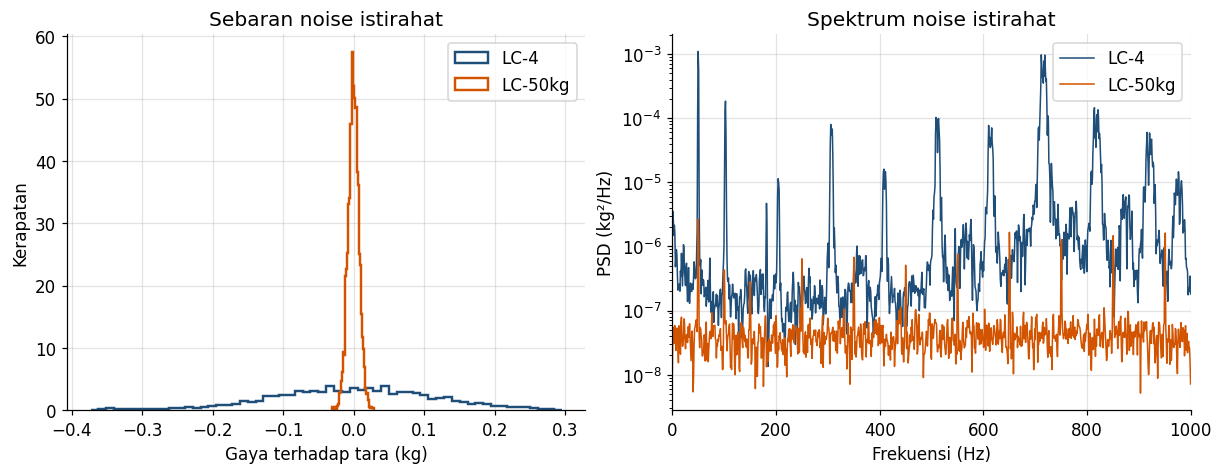

LC-4: RMS 118.0 g, puncak istirahat 295 g, lembah -373 g, n = 6999
  tiga nada terbesar: 50 Hz (1.1e-03 kg²/Hz), 712 Hz (9.8e-04 kg²/Hz), 103 Hz (1.9e-04 kg²/Hz)
LC-50kg: RMS 7.7 g, puncak istirahat 28 g, lembah -30 g, n = 7000
  tiga nada terbesar: 50 Hz (2.7e-06 kg²/Hz), 650 Hz (1.7e-06 kg²/Hz), 851 Hz (1.5e-06 kg²/Hz)
PSD dekat 50 Hz: LC-4 / LC-50kg = 413×. Nada LC-50kg ada, tetapi sangat kecil dibanding LC-4.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)

ax = axes[0]
for name, item in raw.items():
    rest = item["force"][item["t"] < REST_END_S]
    ax.hist(rest, bins=60, density=True, histtype="step", lw=1.6, color=C[name], label=name)
ax.set_xlabel("Gaya terhadap tara (kg)")
ax.set_ylabel("Kerapatan")
ax.set_title("Sebaran noise istirahat")
ax.legend()

ax = axes[1]
for name, item in raw.items():
    rest = item["force"][item["t"] < REST_END_S]
    freq, pxx = signal.welch(rest, fs=item["fs"], nperseg=2048, detrend="constant")
    ax.semilogy(freq, pxx, color=C[name], label=name)
ax.set_xlabel("Frekuensi (Hz)")
ax.set_ylabel("PSD (kg²/Hz)")
ax.set_title("Spektrum noise istirahat")
ax.set_xlim(0, raw["LC-4"]["fs"] / 2)
ax.legend()
plt.show()

psd_50 = {}
for name, item in raw.items():
    rest = item["force"][item["t"] < REST_END_S]
    rms = float(np.sqrt(np.mean(rest ** 2)))
    print(
        f"{name}: RMS {rms * 1e3:.1f} g, "
        f"puncak istirahat {rest.max() * 1e3:.0f} g, "
        f"lembah {rest.min() * 1e3:.0f} g, "
        f"n = {rest.size}"
    )
    freq, pxx = signal.welch(rest, fs=item["fs"], nperseg=2048, detrend="constant")
    psd_50[name] = float(pxx[np.argmin(np.abs(freq - 50))])
    band = (freq >= 20) & (freq <= 900)
    med = float(np.median(pxx[band]))
    peaks, _ = signal.find_peaks(pxx, height=med * 30, distance=6)
    peaks = peaks[(freq[peaks] >= 20) & (freq[peaks] <= 900)]
    order = np.argsort(pxx[peaks])[::-1]
    kept = []
    for i in order:
        if any(abs(freq[peaks[i]] - freq[peaks[j]]) < 15 for j in kept):
            continue
        kept.append(int(i))
        if len(kept) == 3:
            break
    nada = ", ".join(f"{freq[peaks[i]]:.0f} Hz ({pxx[peaks[i]]:.1e} kg²/Hz)" for i in kept)
    print(f"  tiga nada terbesar: {nada}")

if psd_50["LC-50kg"] > 0:
    print(
        f"PSD dekat 50 Hz: LC-4 / LC-50kg = {psd_50['LC-4'] / psd_50['LC-50kg']:.0f}×. "
        "Nada LC-50kg ada, tetapi sangat kecil dibanding LC-4."
    )

## 4. Deteksi sentuhan

Event dipotong dengan histeresis pada sinyal rata-rata 10 ms: naik saat melewati 0,8 kg, turun saat kembali ke 0,35 kg. Ambang itu berada di atas puncak noise istirahat LC-4 (~0,3 kg).

- **Puncak** = maksimum sinyal rata-rata di dalam jendela (supaya satu sampel noise tidak mengangkat puncak LC-4).
- **Impuls** = integral gaya positif pada sinyal mentah di jendela yang sama.
- **Onset** = waktu tembus 0,8 kg pada sinyal rata-rata, diinterpolasi antar sampel.

In [5]:
def describe_events(name):
    item = raw[name]
    t = item["t"]
    mask = hysteresis_mask(item["smooth"], ON_KG, OFF_KG)
    events = []
    for start, end in segments_from_mask(mask):
        if end <= start:
            continue
        duration = float(t[end - 1] - t[start])
        peak = float(item["smooth"][start:end].max())
        if duration < MIN_DUR_S or peak < MIN_PEAK_KG:
            continue
        window_force = item["force"][start:end]
        positive = np.clip(window_force, 0, None)
        impulse = float(np.trapz(positive, t[start:end]))
        i_peak = start + int(np.argmax(item["smooth"][start:end]))
        t_peak = float(t[i_peak])
        onset_0 = max(0, start - 1)
        t_onset = crossing_time(t[onset_0:end], item["smooth"][onset_0:end], ON_KG)
        if not np.isfinite(t_onset):
            t_onset = float(t[start])
        # 10% puncak terjadi sebelum ambang 0,8 kg, jadi jendela naik
        # dimulai dari sampel terakhir yang masih di bawah 10% puncak.
        lookback = max(0, start - int(round(0.40 / item["dt"])))
        rise_y = item["smooth"][lookback:i_peak + 1]
        rise_t = t[lookback:i_peak + 1]
        below = np.flatnonzero(rise_y < 0.1 * peak)
        if len(below):
            origin = int(below[-1])
            t10 = crossing_time(rise_t[origin:], rise_y[origin:], 0.1 * peak)
            t90 = crossing_time(rise_t[origin:], rise_y[origin:], 0.9 * peak)
        else:
            t10 = np.nan
            t90 = np.nan
        events.append({
            "sensor": name,
            "i0": int(start),
            "i1": int(end),
            "t_onset": float(t_onset),
            "t_offset": float(t[end - 1]),
            "t_peak": t_peak,
            "duration_s": duration,
            "peak_kg": peak,
            "peak_raw_kg": float(window_force.max()),
            "impulse_kg_s": impulse,
            "rise_10_90_ms": (t90 - t10) * 1e3 if np.isfinite(t10) and np.isfinite(t90) else np.nan,
        })
    return events


events = {name: describe_events(name) for name in raw}

used = set()
pairs = []
for event_a in events["LC-4"]:
    candidates = []
    for k, event_b in enumerate(events["LC-50kg"]):
        if k in used:
            continue
        candidates.append((k, abs(event_b["t_onset"] - event_a["t_onset"])))
    if not candidates:
        continue
    k, gap = min(candidates, key=lambda item: item[1])
    if gap <= MAX_PAIR_S:
        used.add(k)
        pairs.append((event_a, events["LC-50kg"][k]))

print(f"Event LC-4: {len(events['LC-4'])}, LC-50kg: {len(events['LC-50kg'])}, berpasangan: {len(pairs)}")
unpaired = len(events["LC-50kg"]) - len(used)
if unpaired:
    print(f"LC-50kg tanpa pasangan: {unpaired}")

rows = []
for n, (a, b) in enumerate(pairs, start=1):
    rows.append({
        "event": n,
        "t_onset_lc4_s": a["t_onset"],
        "t_onset_lc50_s": b["t_onset"],
        "dt_onset_ms": (a["t_onset"] - b["t_onset"]) * 1e3,
        "dt_peak_ms": (a["t_peak"] - b["t_peak"]) * 1e3,
        "peak_lc4_kg": a["peak_kg"],
        "peak_lc50_kg": b["peak_kg"],
        "ratio_peak": a["peak_kg"] / b["peak_kg"],
        "impulse_lc4": a["impulse_kg_s"],
        "impulse_lc50": b["impulse_kg_s"],
        "ratio_impulse": a["impulse_kg_s"] / b["impulse_kg_s"],
        "rise_lc4_ms": a["rise_10_90_ms"],
        "rise_lc50_ms": b["rise_10_90_ms"],
        "dur_lc4_s": a["duration_s"],
        "dur_lc50_s": b["duration_s"],
    })

tabel = pd.DataFrame(rows)
display(tabel.round({
    "t_onset_lc4_s": 3,
    "t_onset_lc50_s": 3,
    "dt_onset_ms": 1,
    "dt_peak_ms": 1,
    "peak_lc4_kg": 2,
    "peak_lc50_kg": 2,
    "ratio_peak": 3,
    "impulse_lc4": 3,
    "impulse_lc50": 3,
    "ratio_impulse": 3,
    "rise_lc4_ms": 1,
    "rise_lc50_ms": 1,
    "dur_lc4_s": 3,
    "dur_lc50_s": 3,
}))

# Sisa tara di luar jendela event.
gap_notes = []
for name, item in raw.items():
    keep = np.ones(len(item["t"]), dtype=bool)
    for event in events[name]:
        keep[event["i0"]:event["i1"]] = False
    drift_g = (float(np.median(item["force"][keep])) - 0.0) * 1e3
    gap_notes.append(f"{name} median di luar event {drift_g:+.1f} g terhadap tara awal")
print("; ".join(gap_notes))

Event LC-4: 9, LC-50kg: 9, berpasangan: 9


,event,t_onset_lc4_s,t_onset_lc50_s,dt_onset_ms,dt_peak_ms,peak_lc4_kg,peak_lc50_kg,ratio_peak,impulse_lc4,impulse_lc50,ratio_impulse,rise_lc4_ms,rise_lc50_ms,dur_lc4_s,dur_lc50_s
0,1,4.031,3.955,75.9,90.5,2.01,1.38,1.454,0.208,0.138,1.501,80.8,85.7,0.137,0.123
1,2,5.911,5.833,77.1,92.0,3.48,2.35,1.480,0.407,0.273,1.491,79.3,81.3,0.179,0.167
2,3,7.910,7.830,80.3,89.0,7.12,4.79,1.486,0.836,0.563,1.485,79.2,80.1,0.197,0.188
3,4,10.023,9.944,78.7,91.5,9.34,6.16,1.516,1.434,0.955,1.501,98.3,98.5,0.258,0.248
4,5,11.846,11.775,71.0,84.0,14.25,9.37,1.520,2.557,1.695,1.509,123.0,127.8,0.354,0.336
5,6,14.042,13.968,74.0,85.5,23.04,15.08,1.528,3.720,2.450,1.518,108.7,113.0,0.346,0.334
6,7,16.049,15.973,76.5,45.5,30.26,23.35,1.296,5.634,3.928,1.434,112.3,127.1,0.361,0.353
7,8,18.105,18.026,79.4,26.5,30.92,28.58,1.082,6.572,5.116,1.284,80.9,106.7,0.343,0.338
8,9,20.207,20.133,73.5,33.0,31.35,31.55,0.994,6.338,5.184,1.223,71.6,97.1,0.331,0.320


LC-4 median di luar event -13.0 g terhadap tara awal; LC-50kg median di luar event +0.7 g terhadap tara awal


## 5. Cuplikan tiga sentuhan

Baris atas dalam kg. Baris bawah dinormalisasi ke puncak masing-masing sensor supaya bentuk dan selisih waktu terlihat tanpa tertutup perbedaan skala. Garis putus-putus adalah waktu puncak.

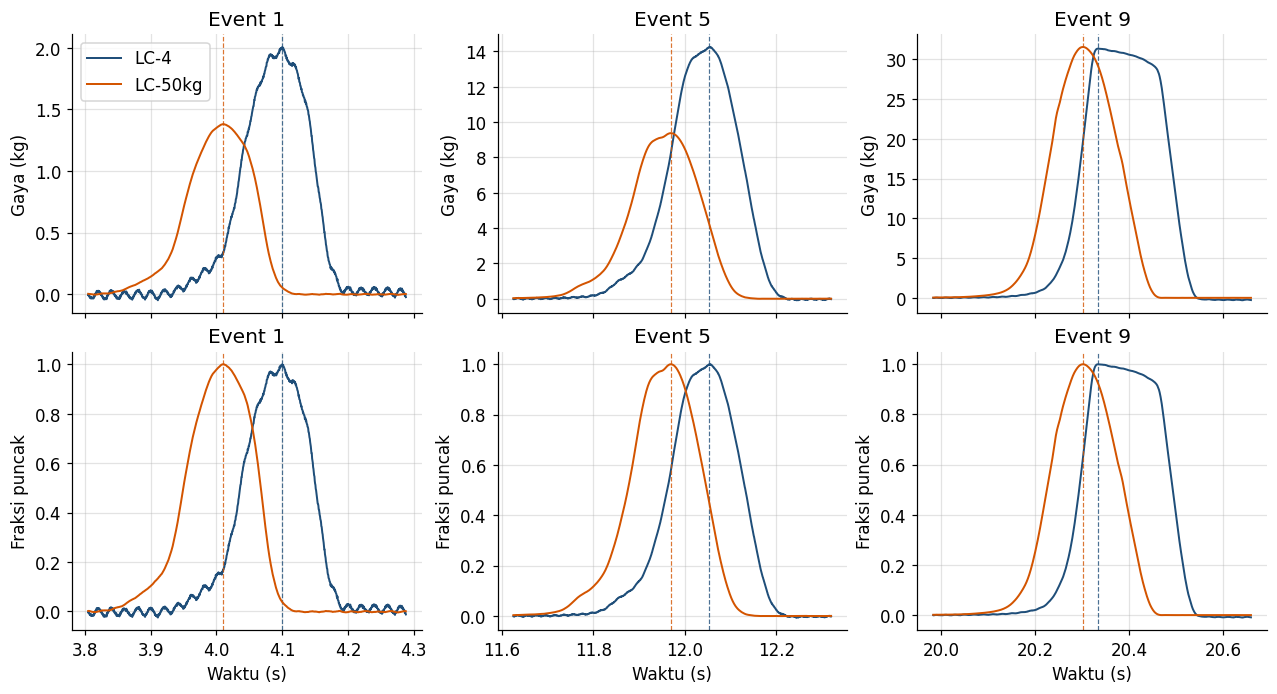

In [6]:
show_ids = sorted({0, len(pairs) // 2, len(pairs) - 1})
fig, axes = plt.subplots(2, len(show_ids), figsize=(11.5, 6.2), sharex="col", constrained_layout=True)
if len(show_ids) == 1:
    axes = np.array([[axes[0]], [axes[1]]])

for col, idx in enumerate(show_ids):
    a, b = pairs[idx]
    t0 = min(a["t_onset"], b["t_onset"]) - 0.15
    t1 = max(a["t_offset"], b["t_offset"]) + 0.12
    series = {"LC-4": a, "LC-50kg": b}
    for row, mode in enumerate(("kg", "norm")):
        ax = axes[row, col]
        for name, event in series.items():
            item = raw[name]
            m = (item["t"] >= t0) & (item["t"] <= t1)
            yy = item["smooth"][m]
            if mode == "norm":
                yy = yy / event["peak_kg"]
            ax.plot(item["t"][m], yy, color=C[name], lw=1.3, label=name)
            ax.axvline(event["t_peak"], color=C[name], ls="--", lw=0.8, alpha=0.8)
        ax.set_title(f"Event {idx + 1}")
        if row == 0:
            ax.set_ylabel("Gaya (kg)")
        else:
            ax.set_ylabel("Fraksi puncak")
            ax.set_xlabel("Waktu (s)")
        if col == 0 and row == 0:
            ax.legend(loc="upper left")

plt.show()

## 6. Geser waktu global

Korelasi silang pada gaya (tara sudah dikurangi) memberi satu angka tunda untuk seluruh rekaman. Angka positif berarti fitur LC-4 muncul lebih lambat daripada LC-50kg.

Header kedua berkas hanya terpaut ~1,5 ms, jadi tunda puluhan milidetik ada di sinyal (respons sensor, jalur mekanik, atau filter di VI kalibrasi), bukan di jam mulai file.

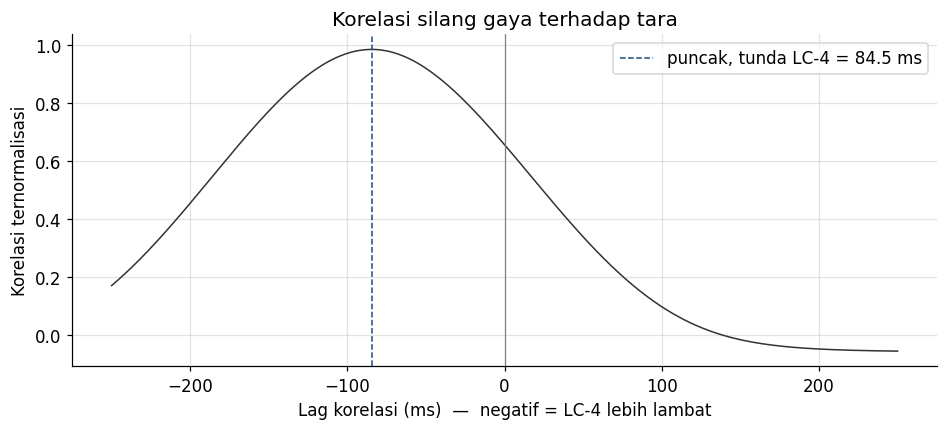

Tunda LC-4 terhadap LC-50kg: 84.5 ms
Korelasi tanpa geser r = 0.657; setelah geser r = 0.986
Median selisih onset (dari tabel event): 76.5 ms
Korelasi silang mengunci energi pulsa besar, sedangkan onset diukur di kaki pulsa. Untuk timer, pakai selisih onset, bukan angka lag korelasi.


,pasangan,n,pearson_r,MAE_kg,RMSE_kg
0,"seluruh sampel, tanpa geser",47230,0.657,1.051,3.673
1,"seluruh sampel, setelah geser",47062,0.986,0.404,1.318
2,"gaya > 1 kg, tanpa geser",6024,0.442,7.475,10.277
3,"gaya > 1 kg, setelah geser",4704,0.976,3.127,4.152


p-value Pearson pada gelombang tidak ditampilkan: puluhan ribu sampel itu saling berautokorelasi, jadi uji signifikansi sampel-independen tidak berlaku. Baca r bersama MAE. MAE seluruh sampel kecil karena didominasi istirahat di dekat nol; MAE saat gaya > 1 kg yang menggambarkan selisih pada sentuhan.


In [7]:
def global_delay(ref_name, mov_name, max_lag_s=MAX_LAG_S):
    ref = raw[ref_name]
    mov = raw[mov_name]
    dt = min(ref["dt"], mov["dt"])
    t0 = max(ref["t"][0], mov["t"][0])
    t1 = min(ref["t"][-1], mov["t"][-1])
    grid = np.arange(t0, t1, dt)
    y_ref = np.interp(grid, ref["t"], ref["force"])
    y_mov = np.interp(grid, mov["t"], mov["force"])
    y_ref = y_ref - y_ref.mean()
    y_mov = y_mov - y_mov.mean()
    corr = signal.correlate(y_ref, y_mov, mode="full", method="fft")
    lags = signal.correlation_lags(len(y_ref), len(y_mov), mode="full")
    sel = np.abs(lags) <= int(round(max_lag_s / dt))
    corr_n = corr[sel] / np.sqrt(np.sum(y_ref ** 2) * np.sum(y_mov ** 2))
    lag_s = lags[sel] * dt
    # Uji sintetis: sinyal yang terlambat menghasilkan lag negatif pada
    # scipy.signal.correlate(referensi, sinyal). Tunda positif = mov lebih lambat.
    peak = int(np.argmax(corr_n))
    delay_s = float(-lag_s[peak])
    r_peak = float(corr_n[peak])
    zero = int(np.argmin(np.abs(lag_s)))
    r_zero = float(corr_n[zero])
    return delay_s, r_peak, r_zero, lag_s, corr_n


delay_s, r_peak, r_zero, lag_s, corr_n = global_delay("LC-50kg", "LC-4")

fig, ax = plt.subplots(figsize=(8.5, 3.8), constrained_layout=True)
ax.plot(lag_s * 1e3, corr_n, color="#333333")
ax.axvline(-delay_s * 1e3, color=C["LC-4"], ls="--", label=f"puncak, tunda LC-4 = {delay_s * 1e3:.1f} ms")
ax.axvline(0, color="0.5", lw=0.8)
ax.set_xlabel("Lag korelasi (ms)  —  negatif = LC-4 lebih lambat")
ax.set_ylabel("Korelasi ternormalisasi")
ax.set_title("Korelasi silang gaya terhadap tara")
ax.legend(loc="upper right")
plt.show()

print(f"Tunda LC-4 terhadap LC-50kg: {delay_s * 1e3:.1f} ms")
print(f"Korelasi tanpa geser r = {r_zero:.3f}; setelah geser r = {r_peak:.3f}")
print(f"Median selisih onset (dari tabel event): {tabel['dt_onset_ms'].median():.1f} ms")
print(
    "Korelasi silang mengunci energi pulsa besar, sedangkan onset diukur di kaki pulsa. "
    "Untuk timer, pakai selisih onset, bukan angka lag korelasi."
)


def aligned_pair(delay_s):
    item4 = raw["LC-4"]
    item5 = raw["LC-50kg"]
    dt = min(item4["dt"], item5["dt"])
    t4 = item4["t"] - delay_s
    t0 = max(t4[0], item5["t"][0])
    t1 = min(t4[-1], item5["t"][-1])
    grid = np.arange(t0, t1, dt)
    y4 = np.interp(grid, t4, item4["force"])
    y5 = np.interp(grid, item5["t"], item5["force"])
    return grid, y4, y5


def mae(a, b):
    return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))


def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))


def pearson_r(a, b):
    r, _p = stats.pearsonr(a, b)
    return float(r)


grid0, y4_raw_t, y5_raw_t = aligned_pair(0.0)
grid, y4_al, y5_al = aligned_pair(delay_s)
active0 = (y4_raw_t > 1.0) | (y5_raw_t > 1.0)
active = (y4_al > 1.0) | (y5_al > 1.0)

baris_gel = []
for label, a, b in (
    ("seluruh sampel, tanpa geser", y4_raw_t, y5_raw_t),
    ("seluruh sampel, setelah geser", y4_al, y5_al),
    ("gaya > 1 kg, tanpa geser", y4_raw_t[active0], y5_raw_t[active0]),
    ("gaya > 1 kg, setelah geser", y4_al[active], y5_al[active]),
):
    baris_gel.append({
        "pasangan": label,
        "n": int(len(a)),
        "pearson_r": pearson_r(a, b),
        "MAE_kg": mae(a, b),
        "RMSE_kg": rmse(a, b),
    })
metrik_gelombang = pd.DataFrame(baris_gel)
display(metrik_gelombang.round(3))
print(
    "p-value Pearson pada gelombang tidak ditampilkan: puluhan ribu sampel itu "
    "saling berautokorelasi, jadi uji signifikansi sampel-independen tidak berlaku. "
    "Baca r bersama MAE. MAE seluruh sampel kecil karena didominasi istirahat di dekat nol; "
    "MAE saat gaya > 1 kg yang menggambarkan selisih pada sentuhan."
)

## 7. Kesepakatan amplitudo

Setiap titik adalah satu sentuhan. Garis abu-abu adalah kesepakatan 1:1. Garis tegas adalah regresi linear sembilan sentuhan. Garis titik-titik adalah faktor proporsional pada sentuhan dengan puncak LC-50kg di bawah 20 kg — di situ rasio masih datar, sebelum tiga sentuhan terberat.

Di bawah gambar ada tabel Pearson r dan MAE untuk puncak serta impuls. r menjawab apakah urutan beban sama. MAE menjawab berapa kilogram rata-rata selisih mutlaknya.

R² garis linear mudah terlihat tinggi karena rentang bebannya lebar. Panel residual yang perlu dibaca: kalau residualnya besar dan berpola, slope dekat 1 belum berarti skala kg sudah cocok.

CCC menghukum bias, tetapi tetap tinggi bila kedua sensor mengikuti tangga beban yang sama. Bland–Altman memakai selisih LC-4 minus LC-50kg. Dengan 9 sentuhan, batas kesepakatan bersifat deskriptif.

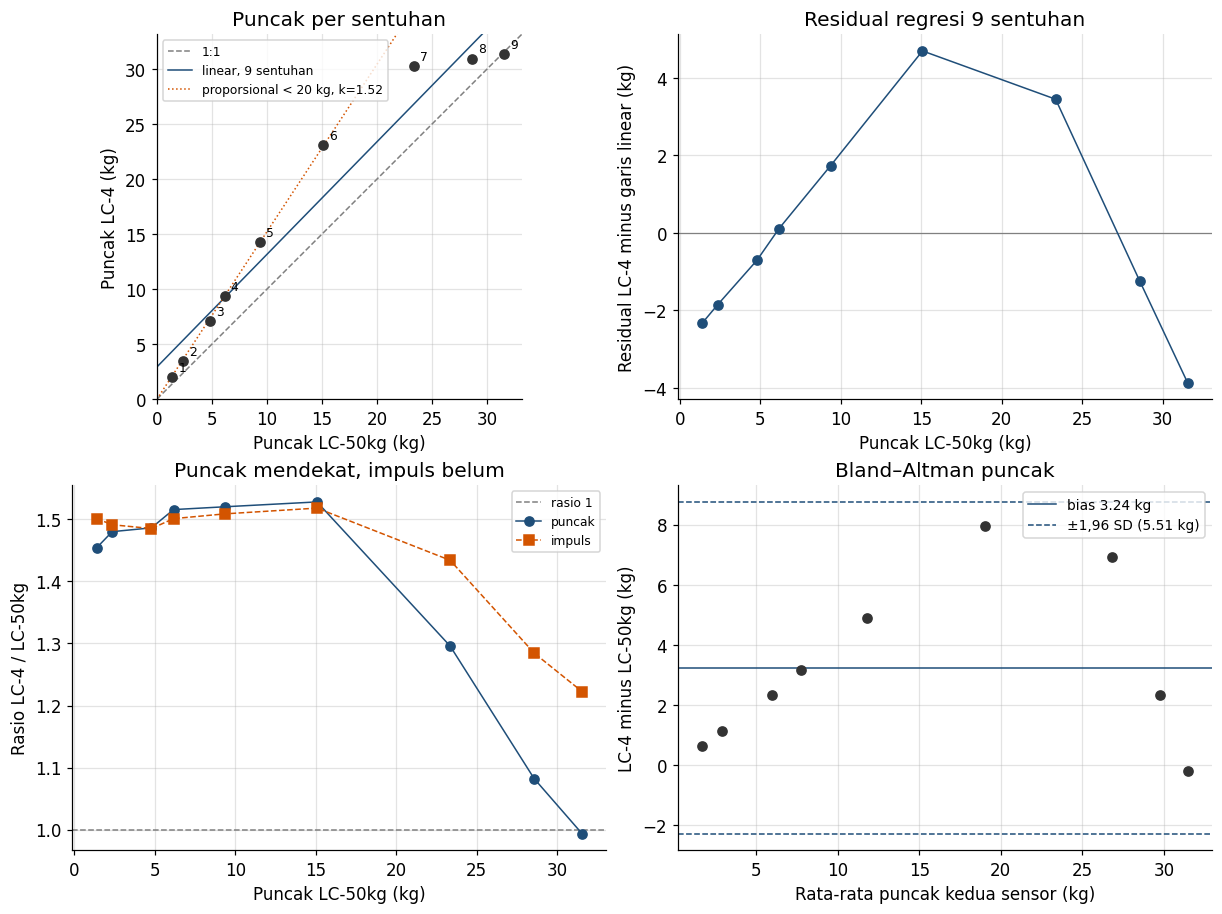

,pasangan,n,pearson_r,pearson_p,MAE,RMSE
0,"puncak, 9 sentuhan",9,0.973,0.0,3.285,4.186
1,"puncak, LC-50kg < 20 kg",6,1.000,0.0,3.351,4.171
2,"impuls, 9 sentuhan",9,0.994,0.0,0.823,1.002
3,"impuls, LC-50kg < 20 kg",6,1.000,0.0,0.515,0.669


Garis linear 9 sentuhan: LC-4 = 2.92 + 1.023 × LC-50kg, R² = 0.947, Pearson r = 0.973, Spearman ρ = 1.000
MAE puncak 9 sentuhan = 3.29 kg. MAE puncak saat LC-50kg < 20 kg = 3.35 kg. MAE impuls 9 sentuhan = 0.823 kg·s.
SE slope = 0.091. Uji slope = 1: p = 0.807. Uji intercept = 0: p = 0.11.
Slope dekat 1 jangan dibaca sebagai skala yang sudah cocok: residualnya [-2.33 -1.85 -0.71  0.11  1.74  4.69  3.45 -1.24 -3.86] kg, besar di beban ringan dan berubah tanda.
Enam sentuhan dengan puncak LC-50kg < 20 kg: rasio puncak 1.45–1.53, faktor proporsional k = 1.522, slope bebas 1.537, intercept -0.15 kg.
CCC puncak (9 sentuhan) = 0.937. CCC tinggi karena kedua sensor mengikuti tangga yang sama, bukan karena selisih kg-nya kecil.
Bland–Altman: bias 3.24 kg, SD selisih 2.81 kg, batas -2.27 … 8.75 kg
Impuls: slope 1.263, intercept 0.228, R² = 0.987, CCC = 0.909
Spearman rasio puncak vs beban LC-50kg: ρ = -0.417, p = 0.265


Tiga sentuhan terberat, rasio puncak 1.30, 1.08, 0.99; rasio impuls 1.43, 1.28, 1.22. Puncak sudah bertemu, luas pulsa belum.


In [8]:
x = tabel["peak_lc50_kg"].to_numpy()
y = tabel["peak_lc4_kg"].to_numpy()
fit = stats.linregress(x, y)
n = len(x)
t_slope = (fit.slope - 1.0) / fit.stderr
p_slope_ne_1 = float(2 * stats.t.sf(abs(t_slope), df=n - 2))
t_icept = fit.intercept / fit.intercept_stderr
p_icept = float(2 * stats.t.sf(abs(t_icept), df=n - 2))
ccc = lin_ccc(x, y)
rho, p_rho = stats.spearmanr(x, y)
bias = float(np.mean(y - x))
sd_diff = float(np.std(y - x, ddof=1))
loa = 1.96 * sd_diff
resid = y - (fit.intercept + fit.slope * x)

# Dataran rasio ~1,5 putus antara sentuhan 15 kg dan 23 kg.
light = x < 20.0
k_light = float(np.sum(x[light] * y[light]) / np.sum(x[light] ** 2))
fit_light = stats.linregress(x[light], y[light])

xi = tabel["impulse_lc50"].to_numpy()
yi = tabel["impulse_lc4"].to_numpy()
fit_i = stats.linregress(xi, yi)

fig, axes = plt.subplots(2, 2, figsize=(11, 8.2), constrained_layout=True)

ax = axes[0, 0]
hi = max(x.max(), y.max()) * 1.05
ax.plot([0, hi], [0, hi], ls="--", color="0.5", label="1:1")
xx = np.linspace(0, hi, 50)
ax.plot(xx, fit.intercept + fit.slope * xx, color=C["LC-4"], label="linear, 9 sentuhan")
ax.plot(xx, k_light * xx, color=C["LC-50kg"], ls=":", label=f"proporsional < 20 kg, k={k_light:.2f}")
ax.scatter(x, y, color="#333333", zorder=3)
for _, row in tabel.iterrows():
    ax.annotate(str(int(row["event"])), (row["peak_lc50_kg"], row["peak_lc4_kg"]),
                textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.set_xlabel("Puncak LC-50kg (kg)")
ax.set_ylabel("Puncak LC-4 (kg)")
ax.set_title("Puncak per sentuhan")
ax.set_xlim(0, hi)
ax.set_ylim(0, hi)
ax.set_aspect("equal", adjustable="box")
ax.legend(loc="upper left", fontsize=8)

ax = axes[0, 1]
ax.axhline(0, color="0.5", lw=0.8)
ax.plot(x, resid, "o-", color=C["LC-4"])
ax.set_xlabel("Puncak LC-50kg (kg)")
ax.set_ylabel("Residual LC-4 minus garis linear (kg)")
ax.set_title("Residual regresi 9 sentuhan")

ax = axes[1, 0]
ax.axhline(1.0, color="0.5", ls="--", label="rasio 1")
ax.plot(x, tabel["ratio_peak"], "o-", color=C["LC-4"], label="puncak")
ax.plot(x, tabel["ratio_impulse"], "s--", color=C["LC-50kg"], label="impuls")
ax.set_xlabel("Puncak LC-50kg (kg)")
ax.set_ylabel("Rasio LC-4 / LC-50kg")
ax.set_title("Puncak mendekat, impuls belum")
ax.legend(fontsize=8)

ax = axes[1, 1]
mean_peak = 0.5 * (x + y)
diff_peak = y - x
ax.axhline(bias, color=C["LC-4"], label=f"bias {bias:.2f} kg")
ax.axhline(bias + loa, color=C["LC-4"], ls="--", label=f"±1,96 SD ({loa:.2f} kg)")
ax.axhline(bias - loa, color=C["LC-4"], ls="--")
ax.scatter(mean_peak, diff_peak, color="#333333", zorder=3)
ax.set_xlabel("Rata-rata puncak kedua sensor (kg)")
ax.set_ylabel("LC-4 minus LC-50kg (kg)")
ax.set_title("Bland–Altman puncak")
ax.legend(loc="best", fontsize=9)

plt.show()

baris_ev = []
for label, a, b in (
    ("puncak, 9 sentuhan", x, y),
    ("puncak, LC-50kg < 20 kg", x[light], y[light]),
    ("impuls, 9 sentuhan", xi, yi),
    ("impuls, LC-50kg < 20 kg", xi[light], yi[light]),
):
    r_ev, p_ev = stats.pearsonr(a, b)
    baris_ev.append({
        "pasangan": label,
        "n": int(len(a)),
        "pearson_r": float(r_ev),
        "pearson_p": float(p_ev),
        "MAE": mae(a, b),
        "RMSE": rmse(a, b),
    })
metrik_sentuhan = pd.DataFrame(baris_ev)
display(metrik_sentuhan.round({"pearson_r": 3, "pearson_p": 4, "MAE": 3, "RMSE": 3}))

print(
    f"Garis linear 9 sentuhan: LC-4 = {fit.intercept:.2f} + {fit.slope:.3f} × LC-50kg, "
    f"R² = {fit.rvalue ** 2:.3f}, Pearson r = {fit.rvalue:.3f}, Spearman ρ = {rho:.3f}"
)
print(
    f"MAE puncak 9 sentuhan = {mae(x, y):.2f} kg. "
    f"MAE puncak saat LC-50kg < 20 kg = {mae(x[light], y[light]):.2f} kg. "
    f"MAE impuls 9 sentuhan = {mae(xi, yi):.3f} kg·s."
)
print(
    f"SE slope = {fit.stderr:.3f}. Uji slope = 1: p = {p_slope_ne_1:.3g}. "
    f"Uji intercept = 0: p = {p_icept:.3g}."
)
print(
    "Slope dekat 1 jangan dibaca sebagai skala yang sudah cocok: "
    f"residualnya {np.round(resid, 2)} kg, besar di beban ringan dan berubah tanda."
)
print(
    f"Enam sentuhan dengan puncak LC-50kg < 20 kg: rasio puncak "
    f"{tabel.loc[light, 'ratio_peak'].min():.2f}–{tabel.loc[light, 'ratio_peak'].max():.2f}, "
    f"faktor proporsional k = {k_light:.3f}, "
    f"slope bebas {fit_light.slope:.3f}, intercept {fit_light.intercept:.2f} kg."
)
print(f"CCC puncak (9 sentuhan) = {ccc:.3f}. CCC tinggi karena kedua sensor mengikuti tangga yang sama, bukan karena selisih kg-nya kecil.")
print(f"Bland–Altman: bias {bias:.2f} kg, SD selisih {sd_diff:.2f} kg, batas {bias - loa:.2f} … {bias + loa:.2f} kg")
print(
    f"Impuls: slope {fit_i.slope:.3f}, intercept {fit_i.intercept:.3f}, "
    f"R² = {fit_i.rvalue ** 2:.3f}, CCC = {lin_ccc(xi, yi):.3f}"
)

rho_ratio, p_ratio = stats.spearmanr(x, tabel["ratio_peak"])
print(f"Spearman rasio puncak vs beban LC-50kg: ρ = {rho_ratio:.3f}, p = {p_ratio:.3g}")
print(
    "Tiga sentuhan terberat, rasio puncak "
    + ", ".join(f"{v:.2f}" for v in tabel['ratio_peak'].iloc[-3:])
    + "; rasio impuls "
    + ", ".join(f"{v:.2f}" for v in tabel['ratio_impulse'].iloc[-3:])
    + ". Puncak sudah bertemu, luas pulsa belum."
)

## 8. Selisih waktu trigger

Untuk tiap sentuhan dan tiap ambang T, dicari waktu pertama sinyal rata-rata 10 ms melewati T. Pencarian dimulai 0,25 s sebelum onset deteksi, masih di daerah istirahat.

Selisih = waktu LC-4 minus waktu LC-50kg. Nilai positif berarti LC-4 memicu lebih lambat. Sentuhan yang puncaknya tidak mencapai T tidak diikutkan pada ambang itu.

,ambang_kg,n,dt_mean_ms,dt_sd_ms,dt_min_ms,dt_max_ms
0,0.5,9,77.23,2.90,70.67,80.09
1,1.0,9,73.39,6.14,59.74,79.34
2,2.0,8,69.64,5.05,61.04,76.15
3,5.0,6,68.09,5.55,59.48,74.02
4,10.0,4,68.42,4.05,64.23,72.71
5,15.0,4,56.99,13.83,38.15,69.52
6,20.0,3,56.38,9.27,46.49,64.88
7,25.0,2,52.73,6.89,47.86,57.60


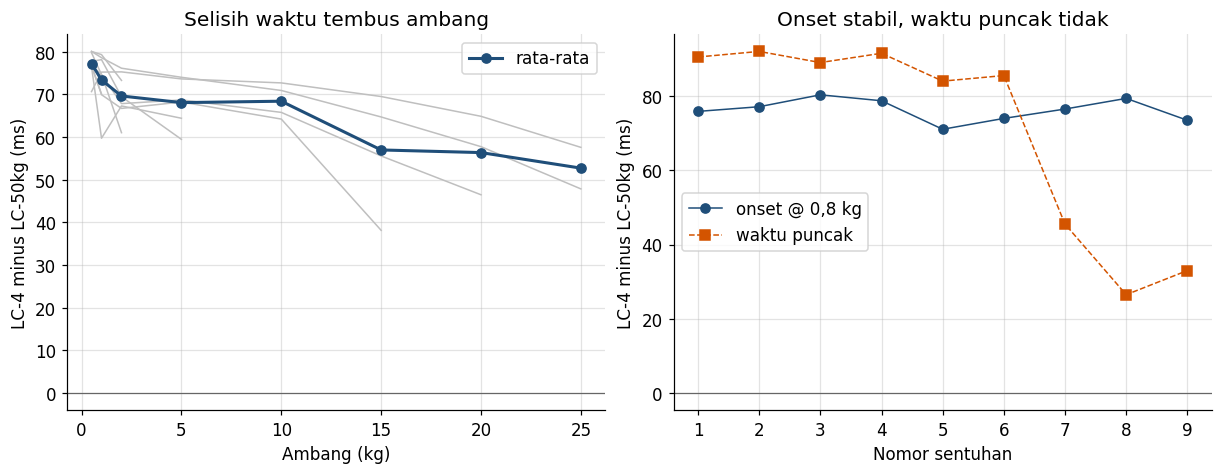

Onset @ 0,8 kg: mean 76.3 ms, SD 3.0 ms, rentang 71.0 … 80.3 ms
Waktu puncak: mean 70.8 ms, SD 27.4 ms, rentang 26.5 … 92.0 ms


In [9]:
sweep_rows = []
for n, (a, b) in enumerate(pairs, start=1):
    for level in THRESHOLDS_KG:
        times = {}
        ok = True
        for name, event in (("LC-4", a), ("LC-50kg", b)):
            item = raw[name]
            t0 = event["t_onset"] - PRE_ROLL_S
            t1 = event["t_offset"] + 0.05
            m = (item["t"] >= t0) & (item["t"] <= t1)
            times[name] = crossing_time(item["t"][m], item["smooth"][m], level)
            if not np.isfinite(times[name]):
                ok = False
        sweep_rows.append({
            "event": n,
            "ambang_kg": level,
            "t_lc4_s": times["LC-4"],
            "t_lc50_s": times["LC-50kg"],
            "dt_ms": (times["LC-4"] - times["LC-50kg"]) * 1e3 if ok else np.nan,
            "peak_lc50_kg": b["peak_kg"],
        })

sweep = pd.DataFrame(sweep_rows)

summary_thr = []
for level, part in sweep.groupby("ambang_kg"):
    valid = part["dt_ms"].dropna()
    summary_thr.append({
        "ambang_kg": level,
        "n": int(valid.size),
        "dt_mean_ms": float(valid.mean()) if len(valid) else np.nan,
        "dt_sd_ms": float(valid.std(ddof=1)) if len(valid) > 1 else np.nan,
        "dt_min_ms": float(valid.min()) if len(valid) else np.nan,
        "dt_max_ms": float(valid.max()) if len(valid) else np.nan,
    })
thr_table = pd.DataFrame(summary_thr)
display(thr_table.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)

ax = axes[0]
for event_id, part in sweep.groupby("event"):
    ax.plot(part["ambang_kg"], part["dt_ms"], color="0.75", lw=1.0)
ax.plot(thr_table["ambang_kg"], thr_table["dt_mean_ms"], "o-", color=C["LC-4"], lw=2.0, label="rata-rata")
ax.axhline(0, color="0.4", lw=0.8)
ax.set_xlabel("Ambang (kg)")
ax.set_ylabel("LC-4 minus LC-50kg (ms)")
ax.set_title("Selisih waktu tembus ambang")
ax.legend()

ax = axes[1]
ax.axhline(0, color="0.4", lw=0.8)
ax.plot(tabel["event"], tabel["dt_onset_ms"], "o-", color=C["LC-4"], label="onset @ 0,8 kg")
ax.plot(tabel["event"], tabel["dt_peak_ms"], "s--", color=C["LC-50kg"], label="waktu puncak")
ax.set_xlabel("Nomor sentuhan")
ax.set_ylabel("LC-4 minus LC-50kg (ms)")
ax.set_title("Onset stabil, waktu puncak tidak")
ax.legend()
plt.show()

print(
    "Onset @ 0,8 kg: "
    f"mean {tabel['dt_onset_ms'].mean():.1f} ms, "
    f"SD {tabel['dt_onset_ms'].std(ddof=1):.1f} ms, "
    f"rentang {tabel['dt_onset_ms'].min():.1f} … {tabel['dt_onset_ms'].max():.1f} ms"
)
print(
    "Waktu puncak: "
    f"mean {tabel['dt_peak_ms'].mean():.1f} ms, "
    f"SD {tabel['dt_peak_ms'].std(ddof=1):.1f} ms, "
    f"rentang {tabel['dt_peak_ms'].min():.1f} … {tabel['dt_peak_ms'].max():.1f} ms"
)

## 9. Ringkasan

Angka di bawah dihitung ulang dari sel ini, jadi ikut berubah jika ambang atau file diganti. Dua CSV ditulis di folder yang sama dengan berkas LVM.

In [10]:
rest_rms = {}
rest_peak = {}
for name, item in raw.items():
    rest = item["force"][item["t"] < REST_END_S]
    rest_rms[name] = float(np.sqrt(np.mean(rest ** 2)))
    rest_peak[name] = float(rest.max())

light = tabel.loc[tabel["peak_lc50_kg"].idxmin()]
print(
    f"Noise RMS istirahat: LC-4 {rest_rms['LC-4'] * 1e3:.0f} g, "
    f"LC-50kg {rest_rms['LC-50kg'] * 1e3:.1f} g "
    f"({rest_rms['LC-4'] / rest_rms['LC-50kg']:.0f}×). "
    f"Puncak noise: {rest_peak['LC-4'] * 1e3:.0f} g vs {rest_peak['LC-50kg'] * 1e3:.0f} g."
)
print(
    f"Sentuhan berpasangan: {len(tabel)}. "
    f"Sentuhan teringan ~{light['peak_lc50_kg']:.2f} kg (LC-50kg) / {light['peak_lc4_kg']:.2f} kg (LC-4), "
    f"masih di atas ambang 0,5 kg dan di atas puncak noise LC-4."
)
print(
    f"Tunda global korelasi silang: LC-4 lebih lambat {delay_s * 1e3:.1f} ms "
    f"(r {r_zero:.3f} → {r_peak:.3f}). "
    f"Onset @ 0,8 kg rata-rata {tabel['dt_onset_ms'].mean():.1f} ± {tabel['dt_onset_ms'].std(ddof=1):.1f} ms, "
    "searah pada semua sentuhan."
)
puncak9 = metrik_sentuhan.loc[metrik_sentuhan["pasangan"] == "puncak, 9 sentuhan"].iloc[0]
puncak6 = metrik_sentuhan.loc[metrik_sentuhan["pasangan"] == "puncak, LC-50kg < 20 kg"].iloc[0]
gel_aktif = metrik_gelombang.loc[metrik_gelombang["pasangan"] == "gaya > 1 kg, setelah geser"].iloc[0]
print(
    f"Pearson puncak 9 sentuhan r = {puncak9['pearson_r']:.3f} (p = {puncak9['pearson_p']:.3g}), "
    f"MAE = {puncak9['MAE']:.2f} kg. "
    f"Pada LC-50kg < 20 kg: r = {puncak6['pearson_r']:.3f}, MAE = {puncak6['MAE']:.2f} kg. "
    f"Gelombang setelah geser, gaya > 1 kg: r = {gel_aktif['pearson_r']:.3f}, MAE = {gel_aktif['MAE_kg']:.2f} kg."
)
print(
    f"Skala: pada enam sentuhan di bawah 20 kg, LC-4 membaca sekitar {k_light:.2f}× LC-50kg. "
    f"Garis lurus ke-9 sentuhan punya slope {fit.slope:.2f} (uji terhadap 1, p = {p_slope_ne_1:.3g}) "
    f"karena tiga sentuhan terberat menariknya; residual beban ringan tetap beberapa kg. "
    f"Bias Bland–Altman {bias:.2f} kg, CCC {ccc:.2f}."
)
print(
    "Pada sentuhan terberat puncak keduanya ~31 kg, tetapi rasio impuls masih di atas 1. "
    "Tanpa massa acuan, penyimpangan tidak bisa dibebankan pada salah satu sensor."
)
print(
    "Untuk timer: selisih tembus ambang LC-4 terhadap LC-50kg tetap puluhan milidetik "
    "pada ambang yang dilampaui kedua sensor. Geser satu konstanta waktu mendekatkan onset; "
    "waktu puncak masih bergantung pada bentuk pulsa."
)

tabel.to_csv(DATA_DIR / "komparasi_event_LC4_LC50kg.csv", index=False, encoding="utf-8-sig")
thr_table.to_csv(DATA_DIR / "komparasi_ambang_LC4_LC50kg.csv", index=False, encoding="utf-8-sig")
gel = metrik_gelombang.rename(columns={"MAE_kg": "MAE", "RMSE_kg": "RMSE"}).copy()
gel["satuan"] = "kg"
gel["pearson_p"] = np.nan
sent = metrik_sentuhan.copy()
sent["satuan"] = np.where(sent["pasangan"].str.startswith("impuls"), "kg·s", "kg")
metrik = pd.concat(
    [gel.assign(kelompok="gelombang"), sent.assign(kelompok="sentuhan")],
    ignore_index=True,
)
metrik.to_csv(DATA_DIR / "komparasi_pearson_mae.csv", index=False, encoding="utf-8-sig")
print("CSV tertulis: komparasi_event_LC4_LC50kg.csv, komparasi_ambang_LC4_LC50kg.csv, komparasi_pearson_mae.csv")

Noise RMS istirahat: LC-4 118 g, LC-50kg 7.7 g (15×). Puncak noise: 295 g vs 28 g.
Sentuhan berpasangan: 9. Sentuhan teringan ~1.38 kg (LC-50kg) / 2.01 kg (LC-4), masih di atas ambang 0,5 kg dan di atas puncak noise LC-4.
Tunda global korelasi silang: LC-4 lebih lambat 84.5 ms (r 0.657 → 0.986). Onset @ 0,8 kg rata-rata 76.3 ± 3.0 ms, searah pada semua sentuhan.
Pearson puncak 9 sentuhan r = 0.973 (p = 1.02e-05), MAE = 3.29 kg. Pada LC-50kg < 20 kg: r = 1.000, MAE = 3.35 kg. Gelombang setelah geser, gaya > 1 kg: r = 0.976, MAE = 3.13 kg.
Skala: pada enam sentuhan di bawah 20 kg, LC-4 membaca sekitar 1.52× LC-50kg. Garis lurus ke-9 sentuhan punya slope 1.02 (uji terhadap 1, p = 0.807) karena tiga sentuhan terberat menariknya; residual beban ringan tetap beberapa kg. Bias Bland–Altman 3.24 kg, CCC 0.94.
Pada sentuhan terberat puncak keduanya ~31 kg, tetapi rasio impuls masih di atas 1. Tanpa massa acuan, penyimpangan tidak bisa dibebankan pada salah satu sensor.
Untuk timer: selisih temb